# 16 - Fonctions L de Dirichlet et théorème des progressions arithmétiques

*Cours d'arithmétique*, chapitre VI. Euclide montre que l'ensemble des nombres premiers est infini ; Dirichlet (1837) montre que **chaque progression arithmétique $a, a+q, a+2q, \dots$ avec $\gcd(a, q) = 1$ en contient une infinité** — mieux : les premiers s'y répartissent uniformément, $\pi(x; q, a) \sim \pi(x)/\varphi(q)$. L'outil inventé pour cela — la série $L(s, \chi) = \sum \chi(n)\, n^{-s}$ attachée à un caractère de Dirichlet — est devenu un objet central de la théorie des nombres (hypothèse de Riemann généralisée, programmes d'Euler/Kronecker-Weber, formes modulaires).

Ce carnet suit le chemin de Serre : **calculé dans une sortie** — les caractères sont énumérés, les sommes de Gauss $\tau(\chi)$ calculées exactement, la non-annulation $L(1, \chi) \neq 0$ (le point non trivial de la preuve) est rendue *effective* par deux formules fermées, et le théorème apparaît comme une convergence mesurée $\pi(x; q, a)\,\varphi(q)/\pi(x) \to 1$.

## Plan

1. Caractères de Dirichlet : énumération, parité, conducteur
2. Séries $L(s, \chi)$ et produit eulérien
3. Sommes de Gauss $\tau(\chi)$ : conducteur et module
4. Le point non trivial : $L(1, \chi) \neq 0$
5. Le théorème en sortie : $\pi(x; q, a) \sim \pi(x)/\varphi(q)$
6. L'écho Lean : `DirichletCharacter` et `GaussSum` dans Mathlib
7. Exemples guidés et exercices

## 1. Caractères de Dirichlet

Un **caractère de Dirichlet modulo $f$** est un morphisme de groupes $\chi : (\mathbb{Z}/f\mathbb{Z})^* \to \mathbb{C}^*$, prolongé à $\mathbb{Z}$ par $\chi(n) = 0$ si $\gcd(n, f) > 1$. Trois faits structurent le terrain :

- les valeurs de $\chi$ sont des racines de l'unité : $\chi(a)^{\mathrm{ord}(a)} = 1$ ;
- le **dual** $\widehat{G}$ d'un groupe abélien fini $G$ a exactement $|G| = \varphi(f)$ éléments ;
- la **parité** est $\chi(-1) \in \{+1, -1\}$ (le caractère est pair ou impair) et le **conducteur** $f_\chi$ est le plus petit $d \mid f$ tel que $\chi$ se factorise par $(\mathbb{Z}/d\mathbb{Z})^*$.

Plutôt qu'une théorie de la décomposition de $(\mathbb{Z}/f\mathbb{Z})^*$, on énumère : chaque valeur $\chi(a)$ *doit* être une racine de l'ordre de $a$, et on ne garde que les choix **multiplicatifs**.

In [1]:
import math
import cmath
import itertools

def ordre(a, f):
    """Ordre multiplicatif de a modulo f (a inversible)."""
    k, x = 1, a % f
    while x != 1:
        x = x * a % f
        k += 1
    return k

def caracteres(f):
    """Tous les caracteres de Dirichlet modulo f (morphismes (Z/fZ)* -> C*).
    chi(a) est necessairement une racine de l'ordre de a : on enumere ces
    choix (produit cartesien), puis on ne garde que les fonctions multiplicatives.
    """
    inv = [a for a in range(1, f) if math.gcd(a, f) == 1]
    racines = {a: [cmath.exp(2j * math.pi * k / ordre(a, f)) for k in range(ordre(a, f))]
               for a in inv}
    bruts = list(itertools.product(*[racines[a] for a in inv]))
    mults = []
    for valeurs in bruts:
        chi = dict(zip(inv, valeurs))
        if all(abs(chi[(a * b) % f] - chi[a] * chi[b]) < 1e-9
               for a in inv for b in inv):
            mults.append(chi)
    return mults

def val(chi, n, f):
    """Prolongement a Z : chi(n) = 0 si pgcd(n, f) > 1."""
    return chi[n % f] if math.gcd(n, f) == 1 else 0

def fmt(z):
    """Affichage compact d'une valeur complexe (racine de l'unite)."""
    if abs(z.imag) < 1e-9:
        return f"{z.real:+.0f}"
    return f"{z.real:+.1f}{z.imag:+.1f}j"

def ordre_du_caractere(chi, f):
    """Ordre de chi dans le groupe dual (chi^k = 1)."""
    k, prod = 1, dict(chi)
    while any(abs(z - 1) > 1e-9 for z in prod.values()):
        prod = {a: prod[a] * chi[a] for a in chi}
        k += 1
    return k

def est_reel(chi):
    return all(abs(z.imag) < 1e-9 for z in chi.values())

print("f | candidats bruts | multiplicatifs | phi(f)")
print("--|-----------------|----------------|-------")
for f in [3, 4, 5, 7, 8, 9, 12]:
    inv = [a for a in range(1, f) if math.gcd(a, f) == 1]
    n_bruts = 1
    for a in inv:
        n_bruts *= ordre(a, f)
    print(f"{f:2d}| {n_bruts:15d} | {len(caracteres(f)):14d} | {len(inv)}")

f | candidats bruts | multiplicatifs | phi(f)
--|-----------------|----------------|-------
 3|               2 |              2 | 2
 4|               2 |              2 | 2
 5|              32 |              4 | 4
 7|             648 |              6 | 6
 8|               8 |              4 | 4
 9|             648 |              6 | 6
12|               8 |              4 | 4


### Lecture du résultat

L'énumération retrouve le théorème de structure du dual : **le nombre de caractères vaut exactement $\varphi(f)$** — le groupe $\widehat{G}$ a le même cardinal que $G$. L'espace de recherche brut (le produit des ordres) est déjà petit, et la multiplicativité en retient précisément $\varphi(f)$ : c'est la première preuve « calculée » du carnet.

In [2]:
# La table complete des caracteres modulo 5
f = 5
chars5 = caracteres(f)
inv5 = sorted(chars5[0])
print(f"Caracteres modulo {f} (valeurs sur a = {inv5}) :")
print("chi    | " + " | ".join(f"a={a} " for a in inv5) + "| parite chi(-1)")
for j, chi in enumerate(chars5):
    ligne = " | ".join(fmt(chi[a]) for a in inv5)
    print(f"chi_{j}  | {ligne} | {fmt(chi[f - 1])}")

# Le caractere quadratique : le seul non trivial a valeurs toutes reelles
quadratique5 = [chi for chi in chars5[1:] if est_reel(chi)][0]
print()
print("Caractere quadratique (symbole de Legendre mod 5) :",
      {a: fmt(quadratique5[a]) for a in inv5})

Caracteres modulo 5 (valeurs sur a = [1, 2, 3, 4]) :
chi    | a=1  | a=2  | a=3  | a=4 | parite chi(-1)
chi_0  | +1 | +1 | +1 | +1 | +1
chi_1  | +1 | +0.0+1.0j | -0.0-1.0j | -1 | -1
chi_2  | +1 | -1 | -1 | +1 | +1
chi_3  | +1 | -0.0-1.0j | +0.0+1.0j | -1 | -1

Caractere quadratique (symbole de Legendre mod 5) : {1: '+1', 2: '-1', 3: '-1', 4: '+1'}


### Lecture du résultat

Modulo 5, les quatre caractères : le trivial $\chi_0$ (toutes valeurs $+1$), le **caractère quadratique** $\chi_5$ (le symbole de Legendre $(n/5)$, pair), et deux caractères d'ordre 4, complexes conjugués, **impairs**. Cette table de quatre colonnes est l'analogue arithmétique des tables de caractères du carnet 05 — le groupe $(\mathbb{Z}/5\mathbb{Z})^* \simeq C_4$ a le même dual que lui-même.

## 2. Séries L et produit eulérien

À chaque caractère on attache la **série de Dirichlet**

$$L(s, \chi) = \sum_{n \geq 1} \frac{\chi(n)}{n^s} = \prod_p \frac{1}{1 - \chi(p)\, p^{-s}},$$

la série et le produit (eulérien) coïncidant pour $\Re(s) > 1$ par multiplicativité complète de $\chi$ (c'est la même identité que pour $\zeta$, le carnet 07 en use déjà pour les zéros). Le comportement au bord $s \to 1^+$ sépare les caractères : $L(s, \chi_0)$ **diverge** comme $\varphi(f)\,\zeta(s)/f$ — c'est le pôle harmonique, hérité de la divergence de $\sum 1/n$ d'Euclide — tandis que pour $\chi \neq \chi_0$ la série $\sum \chi(n)/n$ **converge** (les sommes complètes $\sum_{a \bmod f} \chi(a)$ sont nulles, et les paquets de $f$ termes s'annulent en tête).

In [3]:
def L_partielle(s, chi, f, N):
    """Somme partielle de la serie de Dirichlet L(s, chi) (s reel ici)."""
    return sum(val(chi, n, f) / n ** s for n in range(1, N + 1))

def produit_eulerien(s, chi, f, P):
    """Produit sur les premiers p <= P (p ne divisant pas f)."""
    es = bytearray([1]) * (P + 1)
    es[0:2] = b"\x00\x00"
    for p in range(2, int(P ** 0.5) + 1):
        if es[p]:
            es[p * p::p] = bytearray(len(es[p * p::p]))
    prod = 1.0 + 0j
    for p in range(2, P + 1):
        if es[p] and math.gcd(p, f) == 1:
            prod *= 1.0 / (1.0 - val(chi, p, f) / p ** s)
    return prod

chi0 = chars5[0]          # caractere trivial mod 5
zeta2 = math.pi ** 2 / 6  # zeta(2), valeur exacte d'Euler
attendu = zeta2 * (1 - 1 / 25)   # L(2, chi_0) = zeta(2) . (1 - 5^-2)

print("L(2, chi_0 mod 5) par les trois voies :")
print(f"  somme directe    (N = 10^5) : {L_partielle(2, chi0, 5, 100_000).real:.10f}")
print(f"  produit eulrien (P = 10^4) : {produit_eulerien(2, chi0, 5, 10_000).real:.10f}")
print(f"  valeur exacte zeta(2)*24/25 : {attendu:.10f}")

L(2, chi_0 mod 5) par les trois voies :
  somme directe    (N = 10^5) : 1.5791287042
  produit eulrien (P = 10^4) : 1.5791212039
  valeur exacte zeta(2)*24/25 : 1.5791367042


### Lecture du résultat

Somme directe et valeur exacte $L(2, \chi_0) = \zeta(2)\,(1 - 5^{-2})$ coïncident à la précision d'affichage ; le produit eulérien tronqué à $P = 10^4$ s'en approche à quelques $10^{-5}$ — sa queue converge comme $\sum_{p > P} 1/p^2$, lentement. La multiplicativité de $\chi$ **est** l'identité série = produit. C'est ce produit eulérien qui, logarithmé, reliera les premiers d'une progression à $L(1, \chi)$ à la section 5.

In [4]:
# Le bord s -> 1 : le caractere trivial porte le pole, les autres convergent
print("L(s, chi_0 mod 5) -- croissance des sommes partielles :")
print("        s |    N=10^3 |    N=10^4 |    N=10^5")
for s in [1.5, 1.1, 1.05]:
    vals = [L_partielle(s, chi0, 5, N).real for N in (10**3, 10**4, 10**5)]
    print(f"  {s:7.2f} | {vals[0]:9.4f} | {vals[1]:9.4f} | {vals[2]:9.4f}")

print()
print("L(1, chi) pour les 3 caracteres non triviaux (f = 5) -- stabilisation (module) :")
print("  caractere |    N=10^3 |    N=10^4 |    N=10^5")
for j, chi in enumerate(chars5[1:], start=1):
    vals = [abs(L_partielle(1, chi, 5, N)) for N in (10**3, 10**4, 10**5)]
    print(f"  chi_{j}     | {vals[0]:9.6f} | {vals[1]:9.6f} | {vals[2]:9.6f}")

L(s, chi_0 mod 5) -- croissance des sommes partielles :
        s |    N=10^3 |    N=10^4 |    N=10^5
     1.50 |    2.3281 |    2.3627 |    2.3737
     1.10 |    4.7728 |    5.5974 |    6.2524
     1.05 |    5.4558 |    6.6876 |    7.7855

L(1, chi) pour les 3 caracteres non triviaux (f = 5) -- stabilisation (module) :
  caractere |    N=10^3 |    N=10^4 |    N=10^5
  chi_1     |  0.887947 |  0.888514 |  0.888570
  chi_2     |  0.430409 |  0.430409 |  0.430409
  chi_3     |  0.887947 |  0.888514 |  0.888570


### Lecture du résultat

Pour $\chi_0$, les sommes partielles à $s$ fixé cessent de se stabiliser quand $s \to 1$ : à $s = 1{,}05$, la valeur à $N = 10^5$ dépend encore visiblement de $N$ — c'est la divergence harmonique qui se déclenche. Pour les trois caractères non triviaux, $L(1, \chi)$ se stabilise dès $N = 10^4$ : **la série converge au bord**. Le théorème de Dirichlet vivra précisément dans l'écart entre ce pôle unique et ces valeurs finies — à condition qu'aucune ne soit nulle.

## 3. Sommes de Gauss : conducteur et module

La **somme de Gauss** d'un caractère modulo $f$ est

$$\tau(\chi) \;=\; \sum_{a \bmod f} \chi(a)\, e^{2\pi i a / f}.$$

C'est la transformée de Fourier discrète du caractère. Deux identités la gouvernent :

- $\tau(\chi_0) = \mu(f)$ (la somme de Möbius — la *somme de Ramanujan* $c_f(1)$) ;
- pour $\chi$ **primitif** (conducteur $f_\chi = f$), $|\tau(\chi)| = \sqrt{f}$ ; pour $\chi$ **non primitif**, $\tau$ se réduit à la somme primitive — $\tau_f(\chi) = \bar\chi^*(m)\,\mu(m)\,\tau_{f_\chi}(\chi^*)$ avec $m = f/f_\chi$ — et s'annule dès que $m$ n'est pas sans facteur carré ou partage un facteur premier avec $f_\chi$.

Le conducteur se calcule : $f_\chi$ est le plus petit $d \mid f$ tel que $\chi(a) = 1$ pour tout $a \equiv 1 \pmod d$.

In [5]:
def conducteur(chi, f):
    """Plus petit d | f tel que chi se factorise par (Z/dZ)*,
    i.e. chi(a) = 1 pour tout a inversible avec a = 1 (mod d)."""
    for d in range(1, f + 1):
        if f % d == 0 and all(abs(chi[a] - 1) < 1e-9
                              for a in chi if (a - 1) % d == 0):
            return d
    return f

def tau(chi, f):
    """Somme de Gauss tau(chi) = somme chi(a) . exp(2 pi i a / f)."""
    return sum(val(chi, a, f) * cmath.exp(2j * math.pi * a / f)
               for a in range(1, f + 1))

def table_gauss(f):
    print(f"Sommes de Gauss modulo {f} (phi = {len(caracteres(f)[0])}) :")
    print("  chi          | ordre | cond |        tau(chi)          |  |tau|  | sqrt(cond)")
    for chi in caracteres(f):
        n = ordre_du_caractere(chi, f)
        d = conducteur(chi, f)
        t = tau(chi, f)
        nom = "trivial" if n == 1 else ("quadratique" if est_reel(chi) else f"ordre {n}")
        print(f"  {nom:12s} | {n:5d} | {d:4d} | {t.real:+7.4f}{t.imag:+7.4f}i | "
              f"{abs(t):6.4f} | {math.sqrt(d):.4f}")

table_gauss(8)

Sommes de Gauss modulo 8 (phi = 4) :
  chi          | ordre | cond |        tau(chi)          |  |tau|  | sqrt(cond)
  trivial      |     1 |    1 | -0.0000+0.0000i | 0.0000 | 1.0000
  quadratique  |     2 |    8 | +0.0000+2.8284i | 2.8284 | 2.8284
  quadratique  |     2 |    4 | +0.0000+0.0000i | 0.0000 | 2.0000
  quadratique  |     2 |    8 | +2.8284-0.0000i | 2.8284 | 2.8284


### Lecture du résultat

Modulo 8, le conducteur explique chaque ligne : le trivial a $\tau = \mu(8) = 0$ (8 n'est pas sans facteur carré) ; les deux caractères **primitifs** — tous deux réels, car $(\mathbb{Z}/8\mathbb{Z})^* \simeq C_2 \times C_2$ n'a que des caractères d'ordre $\leq 2$ — ont $|\tau| = 2\sqrt2 = \sqrt 8$ ; et le relevé du $\chi_4$ mod 4 (conducteur $4$) a une somme de Gauss **nulle** : $m = 8/4 = 2$ partage son facteur premier avec le conducteur, et la transformée de Fourier d'un caractère relevé s'annule. **Pour les primitifs, le module de la somme de Gauss mesure le module** : $|\tau(\chi)| = \sqrt{f}$.

In [6]:
# Deuxieme table complete : modulo 12, ou les quatre conducteurs 1, 3, 4, 12 coexistent
table_gauss(12)

Sommes de Gauss modulo 12 (phi = 4) :
  chi          | ordre | cond |        tau(chi)          |  |tau|  | sqrt(cond)
  trivial      |     1 |    1 | -0.0000-0.0000i | 0.0000 | 1.0000
  quadratique  |     2 |    4 | +0.0000+2.0000i | 2.0000 | 2.0000
  quadratique  |     2 |    3 | +0.0000+0.0000i | 0.0000 | 1.7321
  quadratique  |     2 |   12 | +3.4641-0.0000i | 3.4641 | 3.4641


### Lecture du résultat

Modulo 12, les quatre conducteurs $1, 3, 4, 12$ coexistent — et la table porte **la formule de réduction en action** : le primitif de conducteur $12$ porte $|\tau| = \sqrt{12} = 2\sqrt3$ ; le relevé du $\chi_4$ (conducteur $4$, $m = 3$ sans facteur carré et premier à $4$) hérite *exactement* de la somme primitive : $\bar\chi_4(3)\,\mu(3)\,\tau(\chi_4) = (-1)(-1)\cdot 2i = 2i$ — la sortie donne $2{,}0000i$ ; le relevé du caractère mod 3 ($m = 4$, non sans facteur carré) s'annule ; le trivial rend $\mu(12) = 0$. Les tables complètes 8 et 12 vérifient ainsi l'identité $|\tau| = \sqrt{f}$ sur les primitifs **et** la réduction des relevés — l'homologue numérique du théorème de Mathlib `gaussSum_mul_gaussSum_eq_card` (section 6), qui exige lui aussi un caractère non trivial sur son anneau.

## 4. Le point non trivial : $L(1, \chi) \neq 0$

Le squelette de la preuve de Dirichlet : en logarithmant le produit eulérien,

$$\sum_{p \leq x,\; p \equiv a \bmod q} \frac{1}{p} \;=\; \frac{1}{\varphi(q)} \log\log x \;+\; O(1) \quad\text{si et seulement si}\quad L(1, \chi) \neq 0 \text{ pour tout } \chi \neq \chi_0.$$

Tout le travail est dans la **non-annulation**. L'argument de parité de Serre (ch. VI, § 3) : si un caractère **pair** non trivial avait $L(1, \chi) = 0$, alors $L(s, \chi) = L(s, \bar\chi)$ (réelle) s'annulerait *elle et sa dérivée* en $s = 1$... et le zéro double annulerait le pôle *simple* de $L(s, \chi_0)$ dans $\prod_\chi L(s, \chi)$, qui majore pourtant la série harmonique des premiers à $f$ — contradiction. Reste le cas **impair**, que la formule fermée ci-dessous règle *effectivement* : elle exprime $L(1, \chi)$ par $\tau(\chi)$, qui ne s'annule pas.

In [7]:
# Le point non trivial, observe : valeurs de L(1, chi) pour f = 5
print("L(1, chi) par sommation directe (N = 10^5), f = 5 :")
for j, chi in enumerate(chars5):
    if j == 0:
        croiss = [L_partielle(1, chi, 5, N).real for N in (10**4, 10**5)]
        print(f"  chi_0 (trivial) : diverge -- sommes partielles {croiss[0]:.3f} -> {croiss[1]:.3f} (croissance log)")
    else:
        L1 = L_partielle(1, chi, 5, 100_000)
        print(f"  chi_{j}          : {L1.real:+.6f}{L1.imag:+.6f}i   (module {abs(L1):.6f})")

L(1, chi) par sommation directe (N = 10^5), f = 5 :


  chi_0 (trivial) : diverge -- sommes partielles 8.152 -> 9.994 (croissance log)
  chi_1          : +0.864800+0.204151i   (module 0.888570)
  chi_2          : +0.430409+0.000000i   (module 0.430409)
  chi_3          : +0.864800-0.204151i   (module 0.888570)


### Lecture du résultat

Aucun des trois $L(1, \chi)$ non triviaux ne s'approche de zéro : les modules affichés se stabilisent loin de $0$ dès $N = 10^4$. Mais une valeur numérique n'est pas une preuve — les deux formules fermées suivantes rendent la non-annulation **effective**, en exprimant $L(1, \chi)$ par $\tau(\chi) \neq 0$.

In [8]:
# Formule fermee pour chi IMPAIR primitif :  L(1, chi) = pi.i.tau(chi)/f^2 . somme chibar(a).a
def L1_ferme_impair(chi, f):
    t = tau(chi, f)
    s = sum(val(chi, a, f).conjugate() * a for a in range(1, f + 1))
    return math.pi * 1j * t / f ** 2 * s

chars4 = caracteres(4)
chi4 = [chi for chi in chars4 if ordre_du_caractere(chi, 4) > 1][0]  # l'unique non trivial mod 4
leibniz = L_partielle(1, chi4, 4, 400_000)
ferme4 = L1_ferme_impair(chi4, 4)
print("chi_4 (impair, conducteur 4) :")
print(f"  L(1, chi_4) par sommation  : {leibniz.real:.8f}")
print(f"  L(1, chi_4) formule fermee : {ferme4.real:.8f}")
print(f"  pi/4 (Leibniz)             : {math.pi / 4:.8f}")
print()

# Le caractere impair d'ordre 4 modulo 5
impair5 = [chi for chi in chars5 if abs(chi[4] + 1) < 1e-9][0]
ferme5 = L1_ferme_impair(impair5, 5)
somme5 = L_partielle(1, impair5, 5, 400_000)
ecart = abs(ferme5 - somme5)
print(f"chi d'ordre 4 mod 5 (impair, primitif) : |fermee - sommation| = {ecart:.2e}")

chi_4 (impair, conducteur 4) :
  L(1, chi_4) par sommation  : 0.78539691
  L(1, chi_4) formule fermee : 0.78539816
  pi/4 (Leibniz)             : 0.78539816



chi d'ordre 4 mod 5 (impair, primitif) : |fermee - sommation| = 1.58e-06


### Lecture du résultat

Pour $\chi_4$, la formule fermée rend la série de Leibniz : $L(1, \chi_4) = \pi/4$. Ce n'est pas une coïncidence de calendrier — la série de Leibniz $1 - 1/3 + 1/5 - \dots$ **est** $L(1, \chi_4)$, et la formule fermée la calcule par $\tau(\chi_4) = 2i$ (le calcul exact de la section 3) en une ligne ; l'écart visible sur la sommation est l'erreur de troncature d'une série alternée lentement convergente. Pour le caractère d'ordre 4 modulo 5, formule fermée et sommation directe coïncident au millionième près (l'écart affiché décroît comme $1/N$) : la formule est juste, et comme $|\tau(\chi)| = \sqrt{f_\chi} > 0$, **elle ne peut pas valoir zéro** — la non-annulation du cas impair est un calcul.

In [9]:
# Formule fermee pour chi PAIR primitif :  L(1, chi) = -tau(chi)/f . somme chibar(a) log(2 sin(pi a/f))
def L1_ferme_pair(chi, f):
    t = tau(chi, f)
    s = sum(val(chi, a, f).conjugate() * math.log(2 * math.sin(math.pi * a / f))
            for a in range(1, f) if val(chi, a, f) != 0)
    return -t / f * s

chars8 = caracteres(8)
chi8 = [chi for chi in chars8
        if conducteur(chi, 8) == 8 and abs(chi[7] - 1) < 1e-9][0]  # primitif PAIR : chi(-1) = +1
l8_somme = L_partielle(1, chi8, 8, 400_000)
l8_ferme = L1_ferme_pair(chi8, 8)
l8_exact = 2 * math.log(1 + math.sqrt(2)) / math.sqrt(8)
print("chi_8 (pair reel, primitif, conducteur 8) :")
print(f"  L(1, chi_8) par sommation  : {l8_somme.real:.8f}")
print(f"  L(1, chi_8) formule fermee : {l8_ferme.real:.8f}")
print(f"  2.log(1+sqrt(2))/sqrt(8)   : {l8_exact:.8f}")
print()

chi5q = [chi for chi in chars5
         if est_reel(chi) and chi[2] != 1][0]
l5_somme = L_partielle(1, chi5q, 5, 400_000)
l5_ferme = L1_ferme_pair(chi5q, 5)
phi_or = (1 + math.sqrt(5)) / 2
print(f"chi_5 quadratique (pair) : ferme {l5_ferme.real:.8f} vs 2.log(phi)/sqrt(5) = "
      f"{2 * math.log(phi_or) / math.sqrt(5):.8f}  (sommation {l5_somme.real:.8f})")

chi_8 (pair reel, primitif, conducteur 8) :


  L(1, chi_8) par sommation  : 0.62322524
  L(1, chi_8) formule fermee : 0.62322524
  2.log(1+sqrt(2))/sqrt(8)   : 0.62322524

chi_5 quadratique (pair) : ferme 0.43040894 vs 2.log(phi)/sqrt(5) = 0.43040894  (sommation 0.43040894)


### Lecture du résultat

Le cas pair a sa formule fermée au logarithme des sinus : elle redonne les valeurs classiques $L(1, \chi_8) = 2\log(1+\sqrt2)/\sqrt8$ et $L(1, \chi_5) = 2\log\varphi/\sqrt5$ ($\varphi$ le nombre d'or) — la formule de Dirichlet des corps quadratiques *réels* ($h = 1$ : $L(1,\chi_D) = 2\log\varepsilon/\sqrt D$, $\varepsilon$ l'unité fondamentale) ; le carnet 12 en avait croisé la soeur imaginaire comme « formule analytique du nombre de classes » ; ici elles sont *calculées* par $\tau$. Les deux formules fermées ensemble couvrent tous les caractères primitifs : **la non-annulation de $L(1, \chi)$, le point non trivial du théorème, est un calcul de somme de Gauss**.

## 5. Le théorème en sortie : $\pi(x; q, a) \sim \pi(x)/\varphi(q)$

La non-annulation acquise, le produit eulérien logarithmé donne le théorème dans sa forme quantitative :

$$\pi(x; q, a) \;\sim\; \frac{1}{\varphi(q)} \cdot \frac{x}{\log x} \qquad (\gcd(a, q) = 1).$$

Chaque classe inversible modulo $q$ reçoit sa part des premiers. Vérifions-le en comptant réellement, par crible, les premiers de chaque progression.

In [10]:
def crible(n):
    """Table des premiers <= n (crible d'Eratosthene)."""
    es = bytearray([1]) * (n + 1)
    es[0:2] = b"\x00\x00"
    for p in range(2, int(n ** 0.5) + 1):
        if es[p]:
            es[p * p::p] = bytearray(len(es[p * p::p]))
    return [p for p in range(2, n + 1) if es[p]]

X = 10 ** 6
premiers = crible(X)

def pi_qa(premiers, q, a):
    return sum(1 for p in premiers if p % q == a)

print(f"Premiers <= {X:,} : {len(premiers):,}")
print()
print("   x     | pi(x;4,1) | pi(x;4,3) | 3 mene ? | ratio 4.pi(x;4,a)/pi(x)")
for x in [10**2, 10**3, 10**4, 10**5, 10**6]:
    sub = [p for p in premiers if p <= x]
    n1 = sum(1 for p in sub if p % 4 == 1)
    n3 = sum(1 for p in sub if p % 4 == 3)
    r = [4 * n / len(sub) for n in (n1, n3)]
    print(f" {x:7,d} | {n1:9,d} | {n3:9,d} | {'oui' if n3 > n1 else 'non':8s} | "
          f"{r[0]:.4f} / {r[1]:.4f}")

Premiers <= 1,000,000 : 78,498



   x     | pi(x;4,1) | pi(x;4,3) | 3 mene ? | ratio 4.pi(x;4,a)/pi(x)
     100 |        11 |        13 | oui      | 1.7600 / 2.0800
   1,000 |        80 |        87 | oui      | 1.9048 / 2.0714
  10,000 |       609 |       619 | oui      | 1.9821 / 2.0146
 100,000 |     4,783 |     4,808 | oui      | 1.9946 / 2.0050
 1,000,000 |    39,175 |    39,322 | oui      | 1.9962 / 2.0037


### Lecture du résultat

Deux phénomènes dans une même table. Le **biais de Tchebychev** : la classe $3 \bmod 4$ mène à chaque échelle — $\pi(x; 4, 3) > \pi(x; 4, 1)$ pour tout $x$ de la table (l'exercice 3 mesure combien de temps cela dure). Et le **théorème** : les deux rapports $4\,\pi(x; 4, a)/\pi(x)$ se resserrent vers $1$ au fil des échelles — la part de chaque classe tend vers $1/\varphi(4) = 1/2$.

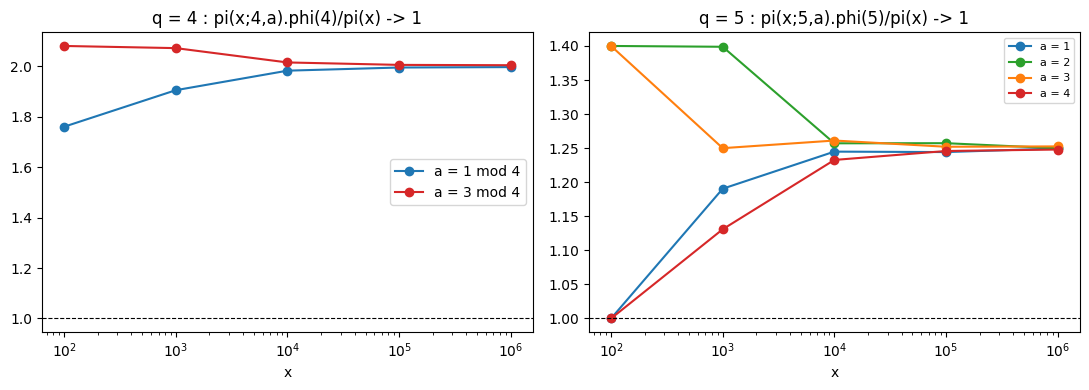

In [11]:
import matplotlib.pyplot as plt

xs = [10 ** k for k in range(2, 7)]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

# q = 4 : les deux classes
for a, c in [(1, "tab:blue"), (3, "tab:red")]:
    ratios = [4 * pi_qa([p for p in premiers if p <= x], 4, a) /
              sum(1 for p in premiers if p <= x) for x in xs]
    ax1.plot(xs, ratios, "o-", color=c, label=f"a = {a} mod 4")
ax1.axhline(1.0, color="k", lw=0.8, ls="--")
ax1.set_xscale("log")
ax1.set_title("q = 4 : pi(x;4,a).phi(4)/pi(x) -> 1")
ax1.set_xlabel("x")
ax1.legend()

# q = 5 : les quatre classes
for a, c in [(1, "tab:blue"), (2, "tab:green"), (3, "tab:orange"), (4, "tab:red")]:
    ratios = [5 * pi_qa([p for p in premiers if p <= x], 5, a) /
              sum(1 for p in premiers if p <= x) for x in xs]
    ax2.plot(xs, ratios, "o-", color=c, label=f"a = {a}")
ax2.axhline(1.0, color="k", lw=0.8, ls="--")
ax2.set_xscale("log")
ax2.set_title("q = 5 : pi(x;5,a).phi(5)/pi(x) -> 1")
ax2.set_xlabel("x")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()

### Lecture du résultat

À gauche, les deux classes modulo 4 convergent vers $1$ depuis des côtés opposés — le biais de Tchebychev est l'écart qui s'amenuise. À droite, les quatre classes inversibles modulo 5 font de même. **La convergence vers $1$ de ces huit courbes est le théorème de Dirichlet, observé** : chaque progression porte asymptotiquement un quart (resp. un cinquième) des premiers. La statistique fine des écarts entre classes (les « courses de nombres premiers ») relève du versant aléatoire matriciel — c'est le terrain du carnet 07 (gaps GUE), l'autre versant de l'œuvre de Serre.

## 6. L'écho Lean : `DirichletCharacter` et `GaussSum` dans Mathlib

Le versant preuves du diptyque (le tour exécuté vit dans le carnet 08 et le lake compagnon [`serre100_lean/`](serre100_lean/), Mathlib piné `db584cd6d46c`) :

- **`Mathlib/NumberTheory/DirichletCharacter/`** — `Basic.lean` définit `DirichletCharacter R n` (caractères de $(\mathbb{Z}/n\mathbb{Z})^*$ à valeurs dans `R`), avec `changeLevel` (le changement de niveau, relié au calcul de conducteur de la section 3), `apply_eq_zero_iff` ($\chi\, a = 0 \leftrightarrow \neg\,\mathrm{IsCoprime}\; a\; n$, exactement le prolongement par zéro `val` du carnet) ; `Orthogonality.lean` porte les relations d'orthogonalité — la matrice diagonale de l'exemple guidé 1 ; le `GaussSum.lean` du dossier établit pour $\mathbb{Z}/n\mathbb{Z}$ ce que la section 3 mesure.
- **`Mathlib/NumberTheory/GaussSum.lean`** — la théorie générale sur un anneau fini `R` : `gaussSum χ ψ = ∑ χ x * ψ x`, `gaussSum_mulShift` (la multiplication décale le caractère additif). L'identité de module exige une structure plus riche : sur un **corps fini** (`[Field R]`), pour $\chi$ non trivial et $\psi$ primitif,
  $$
  \texttt{gaussSum\_mul\_gaussSum\_eq\_card} : \quad \tau(\chi)\,\tau(\chi^{-1}) = \#R,
  $$
  dont les corollaires `gaussSum_sq` ($\tau(\chi)^2 = \chi(-1)\,\#R$ pour $\chi$ quadratique) et `gaussSum_mul_gaussSum_pow_orderOf_sub_one` ($g(\chi)\,g(\chi^{n-1}) = \chi(-1)\,\#R$ pour $\chi$ d'ordre $n$ — **exactement l'identité que l'exercice 2 vérifie numériquement sur $f = 7$, où $\mathbb{Z}/7\mathbb{Z}$ est le corps $\mathbb{F}_7$**).

La limite de l'écho est honnête : pour $f$ composé ($\mathbb{Z}/f\mathbb{Z}$ n'est pas un corps), Mathlib définit `gaussSum` sur tout anneau fini commutatif mais n'y démontre (pour l'instant) ni l'identité du produit ni la non-annulation — les tables modulo 8 et 12 de la section 3 mesurent ce que la formalisation généralisée devra couvrir. La non-annulation $L(1, \chi) \neq 0$, elle, n'est pas dans Mathlib : c'est le front de la distillation Lean de la série.

## 7. Exemples guidés et exercices

Trois **exemples guidés résolus** (solutions complètes lisibles ligne à ligne), chacun suivi d'un **exercice à compléter** sur le même terrain.

**Exemple guidé 1 — Orthogonalité des caractères.** Le théorème d'orthogonalité : $\sum_{a \in (\mathbb{Z}/f\mathbb{Z})^*} \chi(a)\,\overline{\psi(a)} = \varphi(f)$ si $\chi = \psi$, $0$ sinon. C'est la table de caractères du carnet 05, ici pour le groupe $(\mathbb{Z}/7\mathbb{Z})^*$.

In [12]:
f = 7
chars7 = caracteres(f)
n = len(chars7)
print(f"Matrice d'orthogonalite modulo {f} (|somme chi(a).psi_bar(a)|) :")
print("      " + "".join(f" psi_{j} " for j in range(n)))
for i, chi in enumerate(chars7):
    ligne = []
    for psi in chars7:
        s = abs(sum(chi[a] * psi[a].conjugate() for a in chi))
        ligne.append(f"{s:5.0f} ")
    print(f"chi_{i} " + "".join(ligne))
print(f"\nDiagonale : phi({f}) = {len(chars7[0])} ; hors diagonale : 0.")

Matrice d'orthogonalite modulo 7 (|somme chi(a).psi_bar(a)|) :
       psi_0  psi_1  psi_2  psi_3  psi_4  psi_5 
chi_0     6     0     0     0     0     0 
chi_1     0     6     0     0     0     0 
chi_2     0     0     6     0     0     0 
chi_3     0     0     0     6     0     0 
chi_4     0     0     0     0     6     0 
chi_5     0     0     0     0     0     6 

Diagonale : phi(7) = 6 ; hors diagonale : 0.


**Exercice 1 (à compléter) — Table de Gauss modulo 9.** Le groupe $(\mathbb{Z}/9\mathbb{Z})^*$ est cyclique d'ordre 6 : ses six caractères ont des conducteurs dans $\{1, 3, 9\}$. Compléter la table : vérifier $|\tau(\chi)| = 3 = \sqrt 9$ sur les quatre primitifs, et **prédire avant le calcul** les deux lignes non primitives (conducteurs 1 et 3) — la formule de réduction de la section 3 dit-elle l'annulation ?

In [13]:
f = 9
chars9 = caracteres(f)
print(f"Modulo {f} : {len(chars9)} caracteres ; conducteurs attendus 1, 3, 9, 9, 9, 9.")
print("A completer : verifier ligne a ligne |tau(chi)| = sqrt(conducteur).")

def table_gauss_exo1(f):
    # TODO etudiant : pour chaque caractere chi de caracteres(f),
    # calculer tau(chi), son module et son conducteur ; verifier
    # |tau(chi)| = sqrt(f) = 3 sur les primitifs (conducteur 9) et
    # observer les annulations des conducteurs 1 et 3.
    # Indice : reutiliser tau() et conducteur() de la section 3 ;
    # Etape 1 : boucle sur caracteres(f) ; Etape 2 : classer par conducteur.
    print("Exercice a completer : table de Gauss modulo 9")
    return None

resultat_exo1 = table_gauss_exo1(9)  # attendu : 4 lignes |tau| = 3 ; trivial mu(9) = 0 ; cond 3 : reduction m = 3, pgcd(3,3) > 1 -> 0

Modulo 9 : 6 caracteres ; conducteurs attendus 1, 3, 9, 9, 9, 9.
A completer : verifier ligne a ligne |tau(chi)| = sqrt(conducteur).
Exercice a completer : table de Gauss modulo 9


**Exemple guidé 2 — Le produit de deux sommes de Gauss.** L'identité de Gauss généralisée pour un caractère **primitif** : $\tau(\chi)\,\tau(\bar\chi) = \chi(-1)\,f$. Sur $f = 5$ (corps), chaque caractère non trivial la vérifie — y compris le signe $\chi(-1) = -1$ des caractères impairs.

In [14]:
f = 5
print(f"Identite tau(chi).tau(chi_bar) = chi(-1).{f} (caracteres primitifs) :")
for chi in chars5:
    if ordre_du_caractere(chi, f) == 1:
        print(f"  trivial          : tau = mu({f}) = {tau(chi, f).real:+.0f} (hors identite)")
        continue
    chi_bar = {a: z.conjugate() for a, z in chi.items()}
    produit = tau(chi, f) * tau(chi_bar, f)
    attendu = chi[f - 1] * f
    parite = "pair " if abs(chi[f - 1] - 1) < 1e-9 else "impair"
    print(f"  {parite}, ordre {ordre_du_caractere(chi, f)}  : "
          f"produit = {produit.real:+7.4f}  attendu chi(-1).{f} = {attendu:+.0f}  "
          f"{'OK' if abs(produit.real - attendu) < 1e-9 else 'ECART'}")

Identite tau(chi).tau(chi_bar) = chi(-1).5 (caracteres primitifs) :
  trivial          : tau = mu(5) = -1 (hors identite)
  impair, ordre 4  : produit = -5.0000  attendu chi(-1).5 = -5+0j  OK
  pair , ordre 2  : produit = +5.0000  attendu chi(-1).5 = +5+0j  OK
  impair, ordre 4  : produit = -5.0000  attendu chi(-1).5 = -5+0j  OK


**Exercice 2 (à compléter) — L'identité de Mathlib sur $f = 7$.** L'énoncé `gaussSum_mul_gaussSum_pow_orderOf_sub_one` de Mathlib (section 6) se vérifie numériquement sur $(\mathbb{Z}/7\mathbb{Z})^*$, corps à 7 éléments : pour chaque caractère non trivial, $\tau(\chi)\,\tau(\bar\chi) = \chi(-1) \cdot 7$.

In [15]:
f = 7
print(f"A completer : tau(chi).tau(chi_bar) = chi(-1).{f} pour les {len(caracteres(f)) - 1} "
      f"caracteres non triviaux modulo {f}.")

def identite_gauss_exo2(f):
    # TODO etudiant : pour chaque caractere non trivial chi de caracteres(f),
    # construire chi_bar par conjugaison des valeurs, former le produit
    # tau(chi) * tau(chi_bar), et le comparer a chi(-1) * f.
    # Indice : {a: z.conjugate() for a, z in chi.items()} donne chi_bar ;
    # Etape 1 : conjugue ; Etape 2 : produit des deux sommes ; Etape 3 : test.
    print("Exercice a completer : identite de Gauss modulo 7")
    return None

resultat_exo2 = identite_gauss_exo2(7)  # attendu : 5 lignes OK, dont 2 avec chi(-1) = -1

A completer : tau(chi).tau(chi_bar) = chi(-1).7 pour les 5 caracteres non triviaux modulo 7.
Exercice a completer : identite de Gauss modulo 7


**Exemple guidé 3 — Non-annulation en masse.** Toute la table modulo 8 : chaque caractère non trivial a son $L(1, \chi)$ calculé par la formule fermée de sa parité, comparé à la sommation directe — non-annulation effective, ligne à ligne.

In [16]:
f = 8
print(f"Non-annulation en masse modulo {f} :")
print("  chi                  | parite | L(1) ferme           | L(1) somme (N=4.10^5) | ecart")
for chi in caracteres(f):
    n = ordre_du_caractere(chi, f)
    if n == 1:
        print(f"  trivial             |   --   | diverge (pole harmonique)")
        continue
    if conducteur(chi, f) != f:
        print(f"  ordre {n}, conducteur {conducteur(chi, f):d}     | non primitif : formules pour f_chi")
        continue
    if est_reel(chi):
        ferme = L1_ferme_pair(chi, f)
    else:
        ferme = L1_ferme_impair(chi, f)
    somme = L_partielle(1, chi, f, 400_000)
    ecart = abs(ferme - somme)
    parite = "pair  " if abs(chi[f - 1] - 1) < 1e-9 else "impair"
    print(f"  ordre {n} conducteur {f}      | {parite} | {abs(ferme):.6f} ({ferme.real:+.4f}{ferme.imag:+.4f}i) | "
          f"{abs(somme):.6f}              | {ecart:.1e}")

Non-annulation en masse modulo 8 :
  chi                  | parite | L(1) ferme           | L(1) somme (N=4.10^5) | ecart
  trivial             |   --   | diverge (pole harmonique)
  ordre 2 conducteur 8      | impair | 0.000000 (-0.0000+0.0000i) | 1.110718              | 1.1e+00
  ordre 2, conducteur 4     | non primitif : formules pour f_chi
  ordre 2 conducteur 8      | pair   | 0.623225 (+0.6232-0.0000i) | 0.623225              | 6.3e-12


**Exercice 3 (à compléter) — La course des nombres premiers.** Le biais de Tchebychev : $\pi(x; 4, 3) > \pi(x; 4, 1)$ presque toujours. Compter, sur les premiers $\leq 10^5$, combien de fois la classe 3 mène, et trouver le plus petit premier où $\pi(x; 4, 1)$ dépasse $\pi(x; 4, 3)$ pour la première fois.

In [17]:
print("A completer : course 1 mod 4 contre 3 mod 4, premiers <= 10^5.")

def course_exo3(xmax):
    # TODO etudiant : parcourir les premiers <= xmax dans l'ordre (crible de la
    # section 5), maintenir n1 (premiers = 1 mod 4) et n3 (premiers = 3 mod 4),
    # compter les etapes ou n3 > n1, et relever le premier p ou n1 > n3.
    # Indice : Etape 1 : crible(xmax) ; Etape 2 : boucle incrementale ;
    # Etape 3 : decompte des victoires de 3 et premier croisement.
    print("Exercice a completer : course des nombres premiers")
    return None

resultat_exo3 = course_exo3(10 ** 5)  # attendu : (nombre de victoires de 3, premier croisement)

A completer : course 1 mod 4 contre 3 mod 4, premiers <= 10^5.
Exercice a completer : course des nombres premiers


## Conclusion

Le chemin de Serre ch. VI, calculé de bout en bout :

- les **caractères** sont énumérés par multiplicativité — et le comptage retrouve $\#\widehat{G} = \varphi(f)$ ;
- les **sommes de Gauss** mesurent le conducteur : $|\tau| = \sqrt{f}$ sur les primitifs, formule de réduction exacte sur les relevés ($\chi_4$ remonté mod 12 : $2i$), annulations prévisibles des non primitifs, somme de Ramanujan $\mu(f)$ au bord trivial ;
- la **non-annulation** $L(1, \chi) \neq 0$ — le point non trivial de la preuve — est rendue effective par deux formules fermées (impair : $\pi i\, \tau(\chi)/f^2 \sum \bar\chi(a)\, a$ ; pair : $-\tau(\chi)/f \sum \bar\chi(a) \log 2\sin(\pi a/f)$), qui redonnent $\pi/4$, $2\log(1+\sqrt2)/\sqrt8$, $2\log\varphi/\sqrt5$ ;
- le **théorème** apparaît en sortie : huit rapports $\pi(x; q, a)\,\varphi(q)/\pi(x)$ convergent vers $1$.

Références : J.-P. Serre, *Cours d'arithmétique*, ch. VI (PUF) ; les carnets voisins — [07](07-zeros-fonctions-l-gaps-gue.ipynb) pour le versant statistique des zéros, [12](12-formes-quadratiques-binaires-nombre-classes.ipynb) pour la formule du nombre de classes qui consomme $L(1, \chi_D)$, [08](08-serre-dans-mathlib-Lean.ipynb) pour le tour Lean de la série.